In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical



TensorFlow version: 2.21.0


In [2]:
# Load MNIST: 60,000 training images and 10,000 test images
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

# Normalize pixel values from [0, 255] to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Convert digit labels (0–9) to one-hot encoded vectors
num_classes = 10
y_train_cat = to_categorical(y_train, num_classes)
y_test_cat = to_categorical(y_test, num_classes)



11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Preprocessing completed.


In [3]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),                         # Convert 28 x 28 image into 784 values
    Dense(128, activation="relu"),     # Hidden layer
    Dense(64, activation="relu"),      # Hidden layer
    Dense(10, activation="softmax")    # Output layer: 10 digit classes
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# SGD = Stochastic Gradient Descent
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.6369 - loss: 1.3404 - val_accuracy: 0.8617 - val_loss: 0.6281
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8518 - loss: 0.5578 - val_accuracy: 0.9010 - val_loss: 0.3865
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8829 - loss: 0.4191 - val_accuracy: 0.9155 - val_loss: 0.3162
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8971 - loss: 0.3638 - val_accuracy: 0.9220 - val_loss: 0.2818
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9054 - loss: 0.3314 - val_accuracy: 0.9280 - val_loss: 0.2597
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9117 - loss: 0.3086 - val_accuracy: 0.9298 - val_loss: 0.2440
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9164 - loss: 0.2908 - val_accuracy: 0.9347 - val_loss: 0.2311
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9208 - loss: 0.2761 - val_accuracy: 0.

In [10]:
test_loss, test_accuracy = model.evaluate(x_test, y_test_cat, verbose=0)

print(f"Test loss: {test_loss}")
print(f"Test accuracy: {test_accuracy}")

Test loss: 0.2400856763124466
Test accuracy: 0.9312000274658203


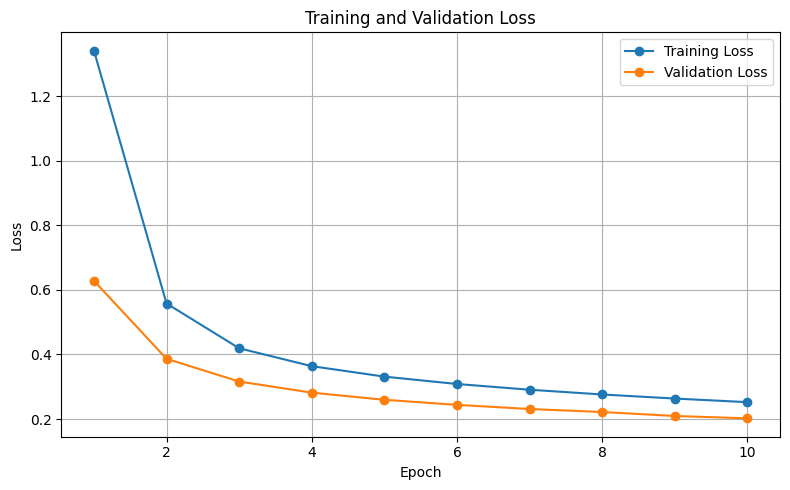

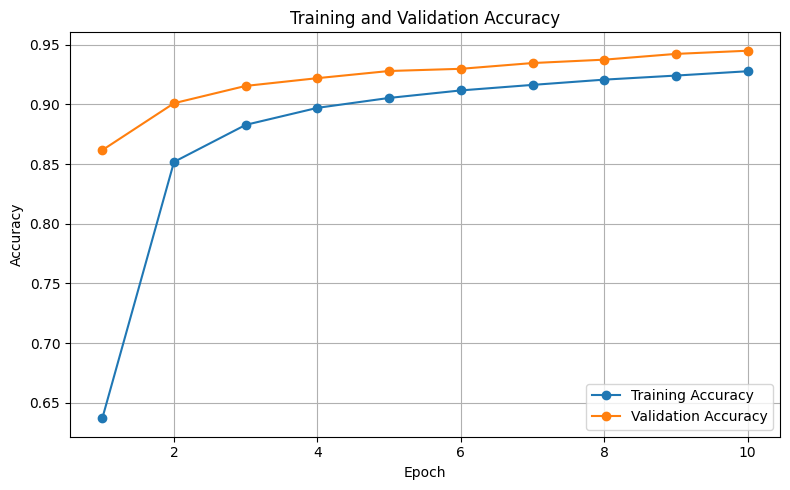

In [6]:
epochs = range(1, len(history.history["loss"]) + 1)

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history["loss"], marker="o", label="Training Loss")
plt.plot(epochs, history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs, history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()